<div align="center">

<!-- Judul Laporan -->
<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h1>
</ul>
<!-- Logo Universitas -->
<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<div align="center">

<!-- Penulis -->
<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>Thya</span><span>(H061241038)</span></li>
</ul>
<br><br>
<!-- Departemen dan Fakultas -->
<p><strong>PRODI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>

<!-- Tahun -->
<p><strong>2026</strong></p>

</div>



## **1. Eksplorasi Emas Menggunakan Metode Induced Polarization (IP)**

Eksplorasi emas dilakukan pada daerah yang memiliki indikasi mineralisasi dan alterasi hidrotermal. Metode IP digunakan untuk mendeteksi zona yang memiliki kemampuan menyimpan muatan listrik, yang dapat berkaitan dengan keberadaan mineral sulfida. Hasil survei digunakan untuk menentukan zona prospek yang perlu diteliti lebih lanjut melalui pengeboran.

R — Role: Bertindaklah sebagai ahli geofisika eksplorasi mineral yang menguasai metode Induced Polarization (IP).

T — Task: Identifikasi zona mineralisasi yang berpotensi mengandung emas berdasarkan pola chargeability bawah permukaan.

C — Context: Suatu wilayah memiliki indikasi alterasi hidrotermal dan singkapan mineral sulfida. Survei dilakukan untuk menentukan target pengeboran eksplorasi.

I — Input: Data chargeability, koordinat elektroda, data resistivitas, dan peta geologi.

K — Constraints: Jangan menyimpulkan keberadaan emas hanya berdasarkan nilai chargeability tinggi. Pertimbangkan kemungkinan mineral sulfida lain.

O — Output: Penampang chargeability, delineasi zona anomali, dan rekomendasi titik pengeboran.

Q — Quality Criteria: Interpretasi harus sesuai dengan pola chargeability, resistivitas, dan kondisi geologi.

V — Optional Verification: Bandingkan hasil dengan data bor atau analisis kadar emas jika tersedia.

Eksekusi 1: Induced Polarization (IP)
Data sintetis: lintasan 100 m, kedalaman model 40 m, dengan zona anomali chargeability di bagian tengah penampang.
Tujuan: menghasilkan visualisasi penampang chargeability dan resistivitas sebagai bahan interpretasi awal zona prospek mineralisasi emas.

METODE INDUCED POLARIZATION (IP) - MODEL SINTETIS
Chargeability minimum : 8.0 mV/V
Chargeability maksimum: 28.0 mV/V
Resistivitas minimum  : 45.0 ohm.m
Resistivitas maksimum : 250.0 ohm.m
Panjang lintasan      : 100 m
Kedalaman model       : 40 m


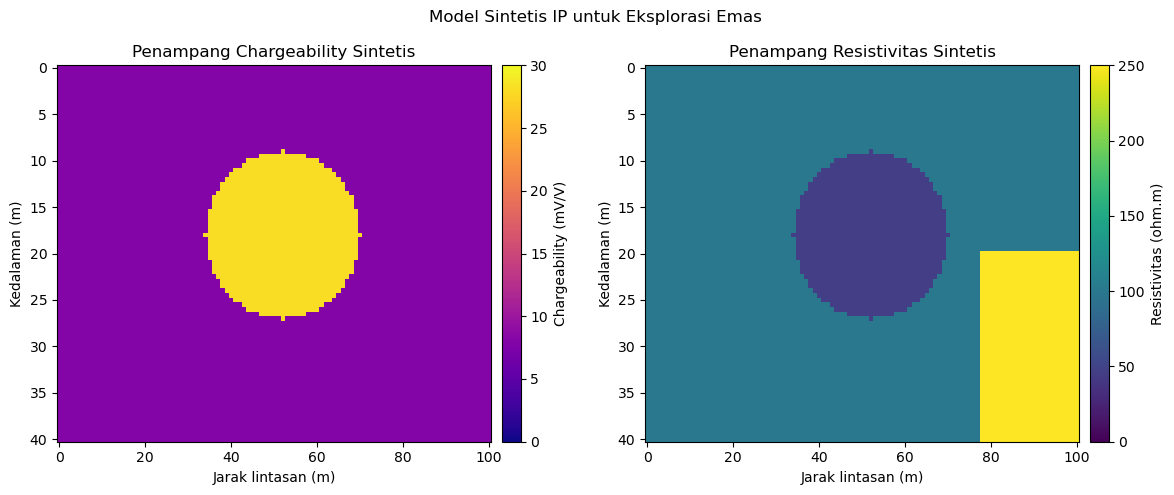

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. PEMBUATAN MODEL IP SINTETIS
# ============================================================

x = np.linspace(0, 100, 101)   # Jarak lintasan (m)
z = np.linspace(0, 40, 81)     # Kedalaman (m)
X, Z = np.meshgrid(x, z)

# Nilai latar belakang
chargeability = np.full_like(X, 8.0)   # mV/V
resistivity = np.full_like(X, 100.0)   # ohm.m

# Zona anomali chargeability tinggi
zone = (((X - 52) / 18)**2 + ((Z - 18) / 9)**2) <= 1
chargeability[zone] = 28.0
resistivity[zone] = 45.0

# Zona resistivitas tinggi di bagian kanan bawah
resistivity[(X >= 78) & (Z >= 20)] = 250.0

# ============================================================
# 2. INFORMASI MODEL
# ============================================================

print("=" * 55)
print("METODE INDUCED POLARIZATION (IP) - MODEL SINTETIS")
print("=" * 55)
print(f"Chargeability minimum : {chargeability.min():.1f} mV/V")
print(f"Chargeability maksimum: {chargeability.max():.1f} mV/V")
print(f"Resistivitas minimum  : {resistivity.min():.1f} ohm.m")
print(f"Resistivitas maksimum : {resistivity.max():.1f} ohm.m")
print("Panjang lintasan      : 100 m")
print("Kedalaman model       : 40 m")
print("=" * 55)

# ============================================================
# 3. VISUALISASI PENAMPANG CHARGEABILITY DAN RESISTIVITAS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Penampang chargeability
im1 = axes[0].pcolormesh(
    X, Z, chargeability,
    shading="auto",
    cmap="plasma",
    vmin=0,
    vmax=30
)

axes[0].invert_yaxis()
axes[0].set_title("Penampang Chargeability Sintetis")
axes[0].set_xlabel("Jarak lintasan (m)")
axes[0].set_ylabel("Kedalaman (m)")
axes[0].set_xticks(np.arange(0, 101, 20))
axes[0].set_yticks(np.arange(0, 41, 5))

cb1 = fig.colorbar(im1, ax=axes[0], pad=0.02)
cb1.set_label("Chargeability (mV/V)")

# Penampang resistivitas
im2 = axes[1].pcolormesh(
    X, Z, resistivity,
    shading="auto",
    cmap="viridis",
    vmin=0,
    vmax=250
)

axes[1].invert_yaxis()
axes[1].set_title("Penampang Resistivitas Sintetis")
axes[1].set_xlabel("Jarak lintasan (m)")
axes[1].set_ylabel("Kedalaman (m)")
axes[1].set_xticks(np.arange(0, 101, 20))
axes[1].set_yticks(np.arange(0, 41, 5))

cb2 = fig.colorbar(im2, ax=axes[1], pad=0.02)
cb2.set_label("Resistivitas (ohm.m)")

fig.suptitle("Model Sintetis IP untuk Eksplorasi Emas")
fig.tight_layout()

# ============================================================
# 4. SIMPAN DAN TAMPILKAN GRAFIK
# ============================================================

nama_file = "penampang_ip_sintetis.png"
fig.savefig(nama_file, dpi=200, bbox_inches="tight")
plt.show()


## **2. Eksplorasi Minyak dan Gas Bumi Menggunakan Metode Seismik Refleksi**

Eksplorasi minyak dan gas bumi dilakukan untuk mengetahui struktur geologi di bawah permukaan yang berpotensi menjadi tempat terakumulasinya hidrokarbon. Metode seismik refleksi digunakan untuk memetakan lapisan batuan, sesar, dan lipatan berdasarkan pantulan gelombang seismik. Hasil interpretasi membantu menentukan lokasi yang berpotensi menjadi target pengeboran eksplorasi.

R — Role: Bertindaklah sebagai ahli geofisika eksplorasi minyak dan gas bumi.

T — Task: Interpretasikan penampang seismik untuk mengidentifikasi struktur geologi yang berpotensi menjadi perangkap hidrokarbon.

C — Context: Suatu cekungan sedimen diperkirakan memiliki potensi minyak dan gas bumi. Survei dilakukan untuk memetakan struktur bawah permukaan sebelum pengeboran.

I — Input: Data seismik refleksi, penampang seismik hasil pengolahan, informasi sumur, dan peta geologi regional.

K — Constraints: Jangan menyatakan keberadaan hidrokarbon hanya berdasarkan struktur antiklin atau sesar. Pertimbangkan unsur sistem petroleum.

O — Output: Interpretasi horizon refleksi, identifikasi sesar dan lipatan, peta struktur, serta usulan target pengeboran.

Q — Quality Criteria: Interpretasi harus memperhatikan kontinuitas reflektor, pola struktur, dan kesesuaian dengan informasi geologi.

V — Optional Verification: Bandingkan interpretasi dengan data sumur atau data seismik 3D jika tersedia.

Eksekusi 2: Seismik Refleksi
Data sintetis: penampang seismik dengan beberapa horizon refleksi, struktur lipatan antiklin, dan sesar pada bawah permukaan.
Tujuan eksekusi: menghasilkan visualisasi penampang seismik sintetis untuk membantu mengenali pola reflektor, mengidentifikasi struktur geologi, dan menentukan target awal eksplorasi minyak dan gas bumi.

MODEL SEISMIK REFLEKSI SINTETIS
Panjang lintasan : 100 m
Rentang waktu    : 0 - 2.5 s
Jumlah horizon   : 4
Struktur         : Antiklin dan sesar
Jenis data       : Data sintetis


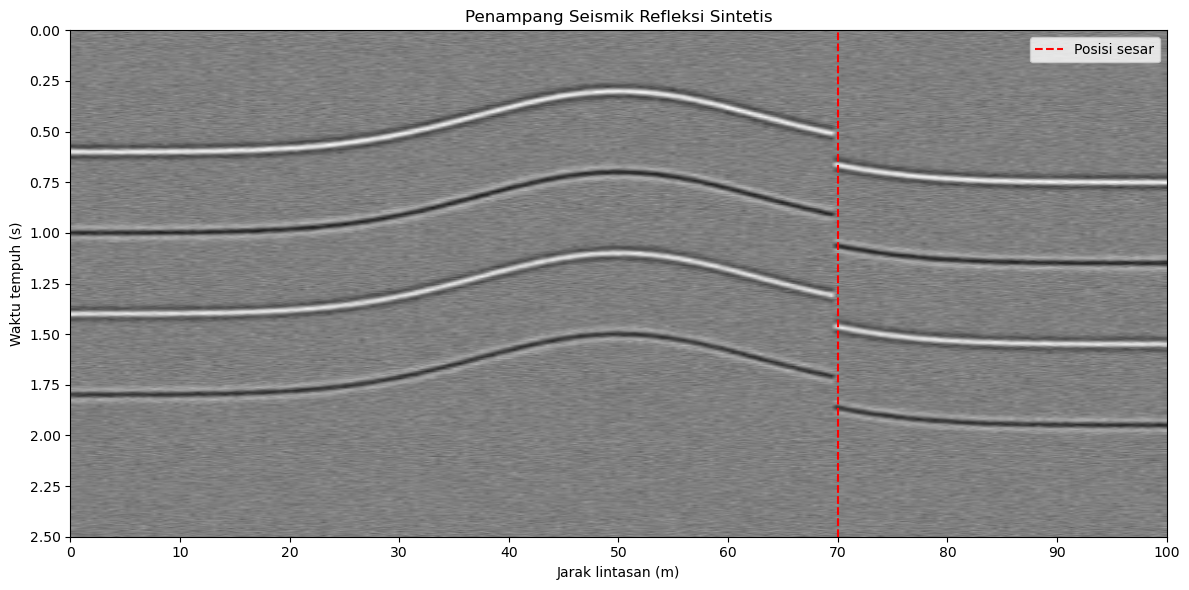

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. PEMBUATAN MODEL SEISMIK SINTETIS
# ============================================================

x = np.linspace(0, 100, 201)       # Jarak lintasan
t = np.linspace(0, 2.5, 501)       # Waktu tempuh (s)

X, T = np.meshgrid(x, t)

# Membuat data amplitudo awal
seismik = np.zeros_like(X)

# Gelombang Ricker
def ricker(tau, frekuensi=15):
    a = (np.pi * frekuensi * tau)**2
    return (1 - 2 * a) * np.exp(-a)

# ============================================================
# 2. PEMBENTUKAN HORIZON REFLEKSI DAN ANTIKLIN
# ============================================================

# Bentuk lipatan antiklin
antiklin = 0.30 * np.exp(-((x - 50) / 18)**2)

# Horizon refleksi
horizon1 = 0.60 - antiklin
horizon2 = 1.00 - antiklin
horizon3 = 1.40 - antiklin
horizon4 = 1.80 - antiklin

# ============================================================
# 3. PEMBENTUKAN SESAR
# ============================================================

# Posisi sesar
posisi_sesar = 70

# Pergeseran horizon pada sisi kanan sesar
pergeseran = 0.15

for i in range(len(x)):
    if x[i] >= posisi_sesar:
        horizon1[i] += pergeseran
        horizon2[i] += pergeseran
        horizon3[i] += pergeseran
        horizon4[i] += pergeseran

# ============================================================
# 4. PEMBENTUKAN SINYAL SEISMIK
# ============================================================

# Amplitudo refleksi setiap horizon
amplitudo = [1.0, -0.8, 0.9, -0.7]
horizon = [horizon1, horizon2, horizon3, horizon4]

for i in range(len(x)):
    for j in range(len(horizon)):
        seismik[:, i] += amplitudo[j] * ricker(
            t - horizon[j][i]
        )

# Menambahkan noise sintetis
np.random.seed(10)
seismik += 0.08 * np.random.randn(*seismik.shape)

# ============================================================
# 5. INFORMASI MODEL
# ============================================================

print("=" * 55)
print("MODEL SEISMIK REFLEKSI SINTETIS")
print("=" * 55)
print("Panjang lintasan : 100 m")
print("Rentang waktu    : 0 - 2.5 s")
print("Jumlah horizon   : 4")
print("Struktur         : Antiklin dan sesar")
print("Jenis data       : Data sintetis")
print("=" * 55)

# ============================================================
# 6. VISUALISASI PENAMPANG SEISMIK
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

batas = np.max(np.abs(seismik))

im = ax.imshow(
    seismik,
    extent=[x.min(), x.max(), t.max(), t.min()],
    aspect="auto",
    cmap="gray",
    vmin=-batas,
    vmax=batas,
    interpolation="bilinear"
)

ax.set_title("Penampang Seismik Refleksi Sintetis")
ax.set_xlabel("Jarak lintasan (m)")
ax.set_ylabel("Waktu tempuh (s)")
ax.set_xticks(np.arange(0, 101, 10))
ax.set_yticks(np.arange(0, 2.51, 0.25))

# Menandai posisi sesar
ax.axvline(
    x=posisi_sesar,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Posisi sesar"
)

ax.legend()
fig.tight_layout()

# ============================================================
# 7. SIMPAN DAN TAMPILKAN GRAFIK
# ============================================================

nama_file = "penampang_seismik_sintetis.png"

fig.savefig(
    nama_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()


## **3. Eksplorasi Panas Bumi Menggunakan Metode Magnetotelurik (MT)**

Eksplorasi panas bumi dilakukan pada daerah vulkanik yang memiliki manifestasi seperti mata air panas dan fumarola. Metode magnetotelurik digunakan untuk mengetahui variasi resistivitas batuan hingga kedalaman tertentu. Data tersebut membantu mengidentifikasi struktur bawah permukaan serta zona yang berpotensi berhubungan dengan sistem panas bumi.

R — Role: Bertindaklah sebagai ahli geofisika eksplorasi panas bumi yang memahami metode Magnetotelurik (MT).

T — Task: Identifikasi zona resistivitas rendah dan struktur bawah permukaan yang berpotensi berhubungan dengan sistem panas bumi.

C — Context: Daerah vulkanik memiliki manifestasi mata air panas dan fumarola. Survei dilakukan untuk memperkirakan struktur sistem panas bumi.

I — Input: Data impedansi MT, resistivitas semu, fase, model inversi resistivitas, dan peta geologi.

K — Constraints: Jangan menganggap semua zona konduktif sebagai reservoir panas bumi. Pertimbangkan kemungkinan lapisan lempung dan struktur geologi.

O — Output: Penampang resistivitas, interpretasi zona konduktif, model konseptual sistem panas bumi, dan target eksplorasi lanjutan.

Q — Quality Criteria: Interpretasi harus didukung oleh pola resistivitas, struktur geologi, dan manifestasi panas bumi.

V — Optional Verification: Bandingkan dengan data geokimia, temperatur, atau data sumur jika tersedia.

Data sintetis: daerah vulkanik dengan lintasan 100 km dan kedalaman model 10 km, yang menunjukkan zona resistivitas rendah di bagian tengah sebagai ilustrasi lapisan konduktif yang mungkin berkaitan dengan sistem panas bumi.
Tujuan: menghasilkan visualisasi penampang resistivitas bawah permukaan untuk mengidentifikasi zona konduktif, memperkirakan struktur sistem panas bumi, dan menentukan target eksplorasi lanjutan.

METODE MAGNETOTELURIK (MT) - MODEL SINTETIS
Resistivitas minimum : 5.0 ohm.m
Resistivitas maksimum: 300.0 ohm.m
Panjang lintasan     : 100 km
Kedalaman model      : 10 km
Zona konduktif       : Bagian tengah penampang


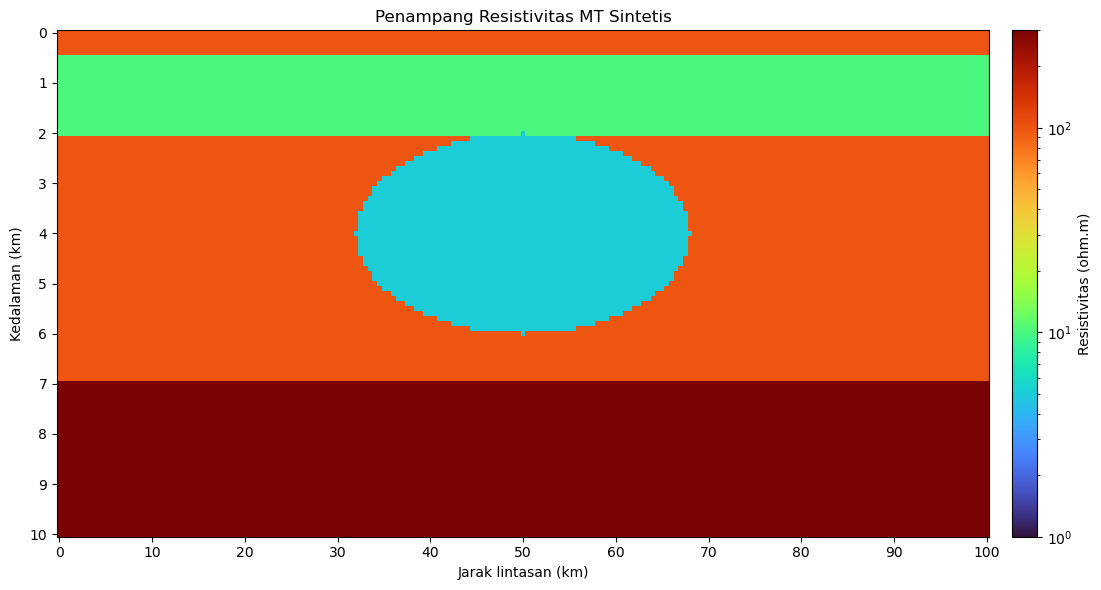

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. PEMBUATAN MODEL RESISTIVITAS MT SINTETIS
# ============================================================

x = np.linspace(0, 100, 201)   # Jarak lintasan (km)
z = np.linspace(0, 10, 101)    # Kedalaman (km)
X, Z = np.meshgrid(x, z)

# Resistivitas latar belakang
rho = np.full_like(X, 100.0)   # ohm.m

# Lapisan konduktif dangkal (ilustrasi clay cap)
rho[(Z >= 0.5) & (Z <= 2.0)] = 10.0

# Zona resistivitas rendah di bagian tengah
zona_konduktif = (
    ((X - 50) / 18) ** 2 +
    ((Z - 4.0) / 2.0) ** 2
) <= 1

rho[zona_konduktif] = 5.0

# Zona resistivitas lebih tinggi di bagian bawah
rho[Z >= 7.0] = 300.0

# ============================================================
# 2. INFORMASI MODEL
# ============================================================

print("=" * 55)
print("METODE MAGNETOTELURIK (MT) - MODEL SINTETIS")
print("=" * 55)
print(f"Resistivitas minimum : {rho.min():.1f} ohm.m")
print(f"Resistivitas maksimum: {rho.max():.1f} ohm.m")
print("Panjang lintasan     : 100 km")
print("Kedalaman model      : 10 km")
print("Zona konduktif       : Bagian tengah penampang")
print("=" * 55)

# ============================================================
# 3. VISUALISASI PENAMPANG RESISTIVITAS
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

im = ax.pcolormesh(
    X, Z, rho,
    shading="auto",
    cmap="turbo",
    norm=plt.matplotlib.colors.LogNorm(
        vmin=1,
        vmax=300
    )
)

ax.invert_yaxis()

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Resistivitas (ohm.m)")

ax.set_xlabel("Jarak lintasan (km)")
ax.set_ylabel("Kedalaman (km)")
ax.set_title("Penampang Resistivitas MT Sintetis")

ax.set_xticks(np.arange(0, 101, 10))
ax.set_yticks(np.arange(0, 10.1, 1))

fig.tight_layout()

# ============================================================
# 4. SIMPAN DAN TAMPILKAN GRAFIK
# ============================================================

nama_file = "penampang_MT_sintetis.png"

fig.savefig(
    nama_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()



## **4. Eksplorasi Bijih Besi Menggunakan Metode Geomagnetik**

Eksplorasi bijih besi dilakukan untuk mengetahui persebaran batuan yang mengandung mineral magnetik di bawah permukaan. Metode geomagnetik digunakan dengan mengukur variasi medan magnet bumi akibat perbedaan sifat kemagnetan batuan. Anomali magnetik yang diperoleh kemudian dianalisis untuk memperkirakan lokasi dan bentuk zona prospek bijih besi.

R — Role: Bertindaklah sebagai ahli geofisika eksplorasi mineral yang menguasai metode geomagnetik.

T — Task: Identifikasi zona anomali magnetik yang berpotensi berhubungan dengan endapan bijih besi di bawah permukaan.

C — Context: Suatu daerah memiliki singkapan batuan yang diduga mengandung mineral magnetik. Survei dilakukan untuk mengetahui persebaran dan kemungkinan kelanjutan endapan ke bawah permukaan.

I — Input: Data medan magnet total, koordinat stasiun, waktu pengukuran, data koreksi variasi harian dan IGRF, serta peta geologi.

K — Constraints: Jangan menyimpulkan bahwa setiap anomali magnetik tinggi merupakan bijih besi. Pertimbangkan jenis mineral, kemagnetan batuan, dan kondisi geologi.

O — Output: Peta anomali magnetik, profil anomali, interpretasi sumber anomali, dan rekomendasi zona target eksplorasi.

Q — Quality Criteria: Hasil harus memperhatikan koreksi data, pola anomali, dan kesesuaian dengan geologi setempat.

V — Optional Verification: Cocokkan zona anomali dengan singkapan, data bor, atau pengukuran suseptibilitas batuan jika tersedia.

Data sintetis: daerah survei berukuran 100 × 100 m dengan anomali magnetik tinggi di bagian tengah sebagai indikasi awal keberadaan batuan bermagnet kuat yang berpotensi berkaitan dengan mineralisasi bijih besi.
Tujuan: menghasilkan visualisasi peta anomali magnetik dan profil anomali untuk mengidentifikasi zona prospek bijih besi serta membantu menentukan target survei lanjutan.

METODE GEOMAGNETIK - MODEL SINTETIS
Anomali minimum : -108.25 nT
Anomali maksimum: 441.07 nT
Panjang area X  : 100 m
Panjang area Y  : 100 m
Jenis data      : Sintetis


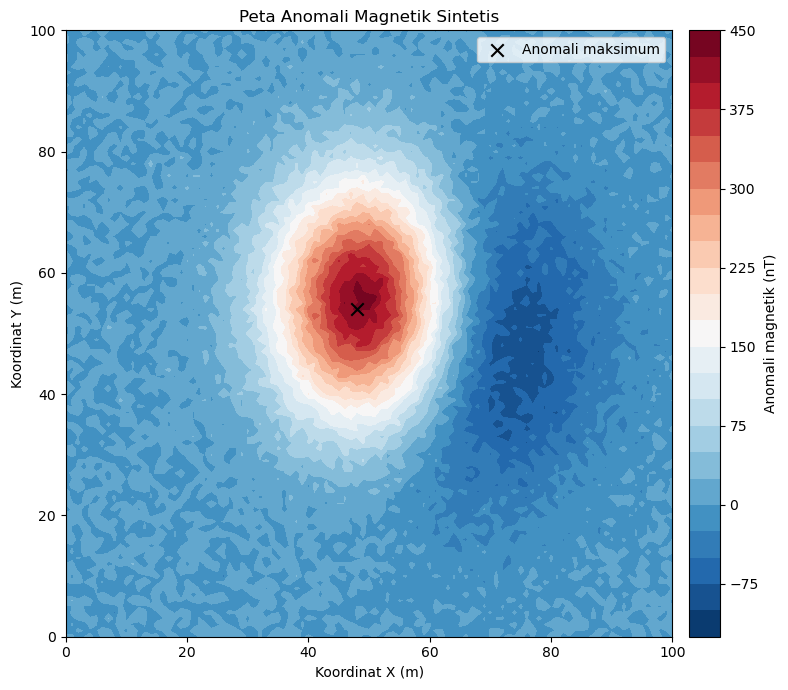

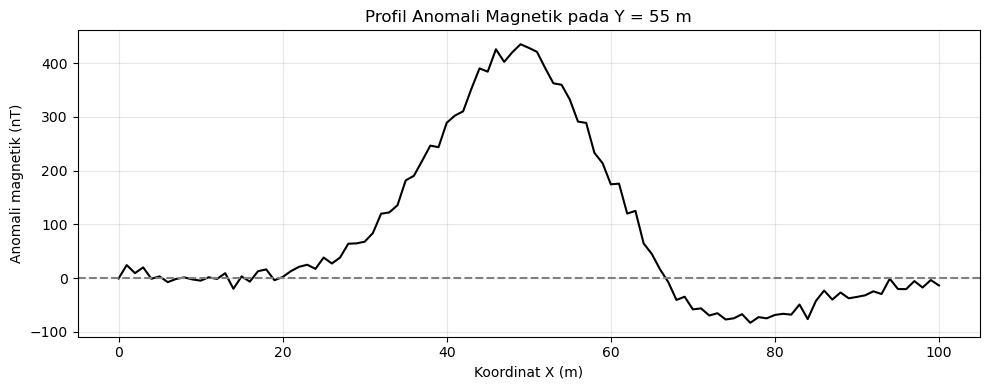

Peta dan profil anomali magnetik berhasil dibuat.


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. PEMBUATAN DATA GEOMAGNETIK SINTETIS
# ============================================================

x = np.linspace(0, 100, 101)  # Koordinat X (m)
y = np.linspace(0, 100, 101)  # Koordinat Y (m)
X, Y = np.meshgrid(x, y)

# Anomali magnetik latar belakang (nT)
anomali = np.zeros_like(X)

# Anomali magnetik positif di bagian tengah
anomali += 500 * np.exp(
    -(((X - 50) / 15) ** 2 + ((Y - 55) / 20) ** 2)
)

# Anomali magnetik negatif di sekitar zona utama
anomali -= 150 * np.exp(
    -(((X - 65) / 20) ** 2 + ((Y - 50) / 25) ** 2)
)

# Menambahkan noise sintetis
np.random.seed(10)
anomali += np.random.normal(0, 10, anomali.shape)

# ============================================================
# 2. INFORMASI MODEL
# ============================================================

print("=" * 55)
print("METODE GEOMAGNETIK - MODEL SINTETIS")
print("=" * 55)
print(f"Anomali minimum : {anomali.min():.2f} nT")
print(f"Anomali maksimum: {anomali.max():.2f} nT")
print("Panjang area X  : 100 m")
print("Panjang area Y  : 100 m")
print("Jenis data      : Sintetis")
print("=" * 55)

# ============================================================
# 3. VISUALISASI PETA ANOMALI MAGNETIK
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.contourf(
    X, Y, anomali,
    levels=25,
    cmap="RdBu_r"
)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Anomali magnetik (nT)")

# Menandai titik anomali maksimum pada model
idx = np.unravel_index(np.argmax(anomali), anomali.shape)
ax.scatter(
    X[idx], Y[idx],
    color="black",
    marker="x",
    s=80,
    label="Anomali maksimum"
)

ax.set_xlabel("Koordinat X (m)")
ax.set_ylabel("Koordinat Y (m)")
ax.set_title("Peta Anomali Magnetik Sintetis")
ax.set_aspect("equal")
ax.legend()
fig.tight_layout()

# ============================================================
# 4. PROFIL ANOMALI MAGNETIK
# ============================================================

indeks_y = np.argmin(np.abs(y - 55))

fig2, ax2 = plt.subplots(figsize=(10, 4))

ax2.plot(
    x,
    anomali[indeks_y, :],
    color="black",
    linewidth=1.5
)

ax2.axhline(0, color="gray", linestyle="--")
ax2.set_xlabel("Koordinat X (m)")
ax2.set_ylabel("Anomali magnetik (nT)")
ax2.set_title("Profil Anomali Magnetik pada Y = 55 m")
ax2.grid(True, alpha=0.3)
fig2.tight_layout()

# ============================================================
# 5. SIMPAN DAN TAMPILKAN GRAFIK
# ============================================================

fig.savefig(
    "peta_anomali_magnetik.png",
    dpi=200,
    bbox_inches="tight"
)

fig2.savefig(
    "profil_anomali_magnetik.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Peta dan profil anomali magnetik berhasil dibuat.")


## **5. Eksplorasi Struktur Bawah Permukaan Dangkal Menggunakan Metode GPR**

Eksplorasi endapan pasir dan kerikil dilakukan pada daerah aluvial untuk mengetahui susunan dan ketebalan lapisan sedimen dangkal. Metode Ground Penetrating Radar (GPR) menggunakan gelombang elektromagnetik untuk menghasilkan gambaran kondisi bawah permukaan. Radargram yang diperoleh dapat digunakan untuk memperkirakan batas lapisan dan menentukan area yang berpotensi mengandung material sedimen.

R — Role: Bertindaklah sebagai ahli geofisika eksplorasi dangkal yang memahami metode Ground Penetrating Radar (GPR).

T — Task: Interpretasikan radargram untuk mengidentifikasi lapisan sedimen dan struktur bawah permukaan yang berpotensi menunjukkan keberadaan endapan pasir dan kerikil.

C — Context: Suatu daerah aluvial sedang diteliti untuk mengetahui persebaran material sedimen yang berpotensi menjadi sumber bahan galian.

I — Input: Data radargram, frekuensi antena, waktu tempuh gelombang radar, posisi lintasan, dan informasi geologi permukaan.

K — Constraints: Pertimbangkan kedalaman penetrasi dan kondisi konduktivitas tanah. Jangan menentukan jenis material hanya berdasarkan pola refleksi radar.

O — Output: Interpretasi radargram, batas lapisan sedimen, perkiraan kedalaman target, dan rekomendasi lokasi survei lanjutan.

Q — Quality Criteria: Interpretasi harus konsisten dengan pola refleksi, waktu tempuh, dan kondisi geologi daerah penelitian.

V — Optional Verification: Bandingkan dengan data bor dangkal atau singkapan sedimen jika tersedia.

Data sintetis: lintasan GPR sepanjang 100 m dengan kedalaman model 5 m menggunakan antena 200 MHz. Radargram dibuat dengan beberapa pola refleksi untuk menggambarkan batas lapisan sedimen dan zona yang berpotensi mengandung pasir serta kerikil.
Tujuan: menghasilkan visualisasi radargram sintetis untuk mengidentifikasi batas lapisan, pola refleksi, dan perkiraan kedalaman target sedimen sebagai bahan interpretasi awal eksplorasi dangkal.

METODE GPR - MODEL RADARGRAM SINTETIS
Panjang lintasan : 100 m
Waktu tempuh     : 0 - 100 ns
Frekuensi antena : 200 MHz
Target           : Batas lapisan sedimen
Jenis data       : Sintetis


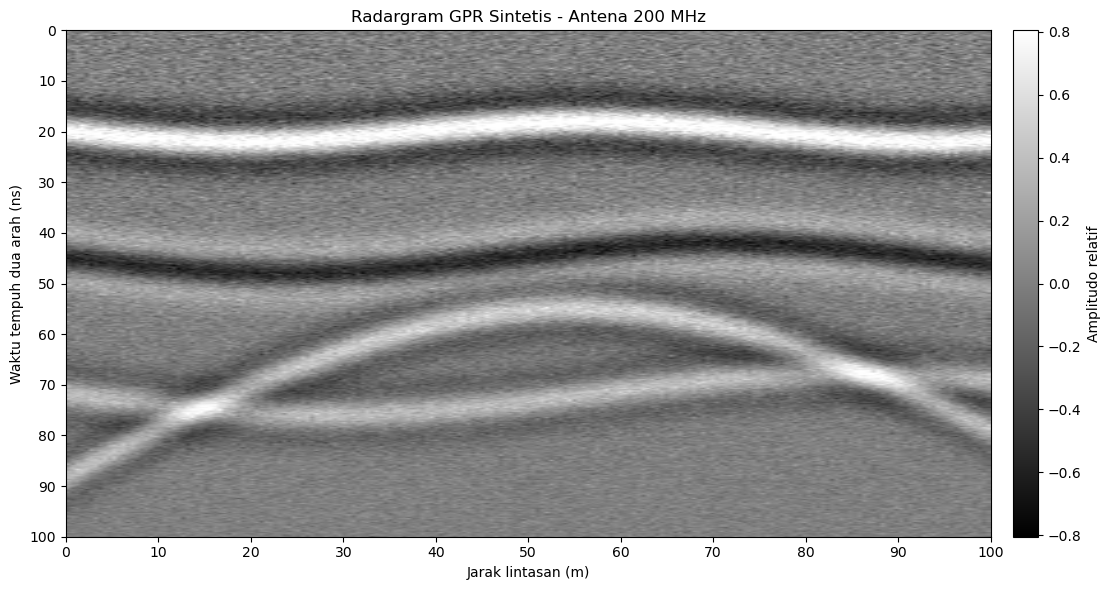

In [8]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. PEMBUATAN MODEL GPR SINTETIS
# ============================================================

x = np.linspace(0, 100, 201)      # Jarak lintasan (m)
t = np.linspace(0, 100, 401)      # Waktu tempuh dua arah (ns)
X, T = np.meshgrid(x, t)

# Radargram awal
radargram = np.zeros_like(X)

# ============================================================
# 2. FUNGSI GELOMBANG RICKER
# ============================================================

def ricker(tau, frekuensi=0.08):
    a = (np.pi * frekuensi * tau) ** 2
    return (1 - 2 * a) * np.exp(-a)

# ============================================================
# 3. PEMBENTUKAN BATAS LAPISAN SEDIMEN
# ============================================================

# Batas reflektor dalam waktu tempuh (ns)
lapisan1 = 20 + 2 * np.sin(x / 12)
lapisan2 = 45 + 3 * np.sin(x / 15)
lapisan3 = 72 + 4 * np.sin(x / 18)

reflektor = [lapisan1, lapisan2, lapisan3]
amplitudo = [1.0, -0.8, 0.7]

for i in range(len(x)):
    for j in range(len(reflektor)):
        radargram[:, i] += amplitudo[j] * ricker(
            t - reflektor[j][i]
        )

# ============================================================
# 4. MENAMBAHKAN POLA HIPERBOLA
# ============================================================

# Ilustrasi objek atau perubahan lokal bawah permukaan
x_objek = 55
t0 = 55
kecepatan = 0.8

waktu_hiperbola = np.sqrt(
    t0**2 + ((x - x_objek) / kecepatan)**2
)

for i in range(len(x)):
    radargram[:, i] += 0.8 * ricker(
        t - waktu_hiperbola[i],
        frekuensi=0.08
    )

# ============================================================
# 5. MENAMBAHKAN NOISE SINTETIS
# ============================================================

np.random.seed(10)
radargram += 0.12 * np.random.randn(*radargram.shape)

# Pelemahan amplitudo terhadap waktu
radargram *= np.exp(-T / 120)

# ============================================================
# 6. INFORMASI MODEL
# ============================================================

print("=" * 55)
print("METODE GPR - MODEL RADARGRAM SINTETIS")
print("=" * 55)
print("Panjang lintasan : 100 m")
print("Waktu tempuh     : 0 - 100 ns")
print("Frekuensi antena : 200 MHz")
print("Target           : Batas lapisan sedimen")
print("Jenis data       : Sintetis")
print("=" * 55)

# ============================================================
# 7. VISUALISASI RADARGRAM
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

batas = np.percentile(np.abs(radargram), 99)

im = ax.imshow(
    radargram,
    extent=[x.min(), x.max(), t.max(), t.min()],
    aspect="auto",
    cmap="gray",
    vmin=-batas,
    vmax=batas,
    interpolation="bilinear"
)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Amplitudo relatif")

ax.set_xlabel("Jarak lintasan (m)")
ax.set_ylabel("Waktu tempuh dua arah (ns)")
ax.set_title("Radargram GPR Sintetis - Antena 200 MHz")
ax.set_xticks(np.arange(0, 101, 10))
ax.set_yticks(np.arange(0, 101, 10))

fig.tight_layout()

# ============================================================
# 8. SIMPAN DAN TAMPILKAN GRAFIK
# ============================================================

nama_file = "radargram_gpr_sintetis.png"

fig.savefig(
    nama_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()